# 10 - Linear regression

A scatter plot can show that two variables move together. It cannot say *by how much*, or how sure we should be about it. This session fits a line through the scatter, puts numbers on it, and asks how much of it to believe.

This notebook covers the following topics:

- Fitting a line - correlation, the formula, `ols`, `fit`, and what to read in the summary
- What is inside a fitted model - `params`, `pvalues`, `conf_int`, R² - the numbers without the table
- The line, and what it misses - predictions, residuals, and the plot that tells you the line is wrong
- More than one explanatory variable - multiple regression, and the coefficient that moves
- Curves - a polynomial, a log, and which R² values you may compare
- Variables that are not numbers - `C()`, the reference category, and interactions
- Fitting many models at once - building formulas in a loop
- Getting the results out - a summary table, a regression table, and files you can put in a report

### What this session covers, and what it does not

Everything here is **ordinary least squares on cross-sectional data**: one row per thing, a numeric outcome, and one or more explanatory variables measured at the same time. That is the workhorse, and it is what the rest of this course has been preparing a table for.

Two whole families of model are **deliberately out of scope**, and it is worth knowing they exist so you do not reach for OLS where it does not belong:

- **A yes/no outcome.** If what you are explaining is *survived or not*, *defaulted or not*, *clicked  or not*, a straight line will happily fit it and will happily predict a probability of 1.4. That needs **logistic regression**.

- **A series through time.** If your rows are months or years of the same thing, consecutive rows are not independent of each other, and two variables that both drift upward will look strongly related when nothing connects them at all. That needs **time-series methods**.

Both are the subject of later courses. Everything in this notebook assumes neither problem applies.

We start the way every notebook in this course starts: imports first, then anything that applies to the whole notebook, then the data.

`statsmodels` is the modeling library. We want its **formula** interface, which lets you describe a model as a short string, and it is conventionally imported as `smf`.

`plt.style.use` goes here too, once, at the top. Every figure below inherits it and no cell has to mention it again - which is the whole point of a style sheet.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

plt.style.use("ggplot")

In [2]:
cars = pd.read_excel("../data/mpg.xlsx")

print(cars.shape)
cars.head()

(398, 8)


,mpg,cylinders,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,140.0,3449,10.5,70,usa,ford torino


`mpg.xlsx` has 398 cars from model years 1970 to 1982, built in the United States, Europe and Japan:

- `mpg` - fuel economy in miles per gallon, so **higher is better**. This is what we are trying to explain
- `cylinders` - the number of cylinders in the engine
- `horsepower` - engine power
- `weight` - in **pounds**
- `acceleration` - seconds from 0 to 60 miles per hour, so **lower is faster**
- `model_year` - stored as two digits: `70` is 1970
- `origin` - where the car was built: `usa`, `europe` or `japan`
- `name` - make and model

The units matter more than usual this week. A regression coefficient is measured in the units of its variables, so a coefficient on `weight` is *miles per gallon per pound*, and it cannot be read without knowing that.

In [3]:
cars.isna().sum()

mpg             0
cylinders       0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

Six missing values in `horsepower`, which is the variable we are about to use.

**`statsmodels` will drop those rows for you, silently.** That is convenient, but a model fitted on 392 rows and a model fitted on 398 rows are different models. We drop them ourselves, so that the number of rows is a decision we made rather than one that happened to us.

We will load the data again at the start of every section and in every exercise, so that nothing depends on what an earlier cell - or your own exercise code - left behind. 

In [4]:
def load_cars(path="../data/mpg.xlsx"):
    """
    Read the car data and drop the cars with no horsepower.

    Parameters
    ----------
    path : str
        Path to the Excel file.

    Returns
    -------
    DataFrame
        One row per car, with the six cars missing horsepower removed.
    """
    cars = pd.read_excel(path)
    cars = cars.dropna(subset=["horsepower"])
    return cars


cars = load_cars()

print("rows used:", len(cars))

rows used: 392


## Fitting a line

Here is fuel economy against engine power, one point per car:

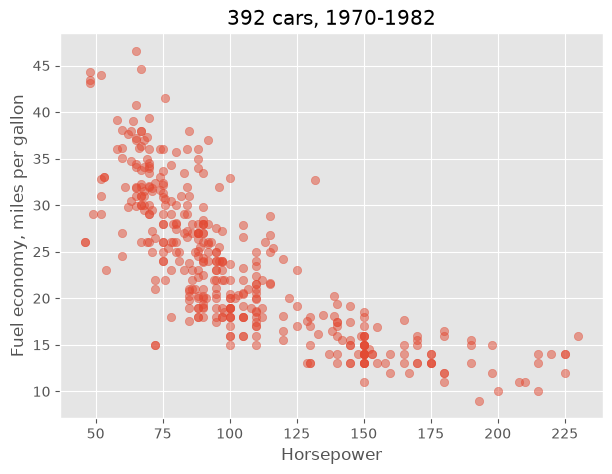

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(cars["horsepower"], cars["mpg"], alpha=0.5)

ax.set_xlabel("Horsepower")
ax.set_ylabel("Fuel economy, miles per gallon")
ax.set_title(f"{len(cars)} cars, 1970-1982")

plt.show()

There is clearly a relationship: more powerful cars go fewer miles on a gallon. The standard one-number summary of how closely two variables move together is the **correlation**, and `pandas` computes it with `.corr()`:

In [6]:
cars["horsepower"].corr(cars["mpg"])

np.float64(-0.7784267838977754)

A correlation runs from -1 to +1. The sign gives the direction, and the closer it is to either end, the closer the points lie to a straight line. **-0.78** is negative and strong.

That is a description, though, and it has no units. A regression turns it into a **sentence with units in it**: how many miles per gallon does a car lose for each extra unit of horsepower?

### What the line is

A straight line through the cloud is described by two numbers:

$$mpg_i = \alpha + \beta \times horsepower_i + \varepsilon_i$$

- $\alpha$ is the **intercept** - where the line crosses the y-axis
- $\beta$ is the **slope** - how much `mpg` changes when `horsepower` goes up by one
- $\varepsilon_i$ is what is left over for car $i$: the vertical distance from the line to the point

There are infinitely many lines you could draw. **Ordinary least squares** picks the one that makes the sum of those leftovers, *squared*, as small as possible. Squared, because otherwise a line could be badly wrong in both directions and the errors would cancel.

**Illustration**: Here are ten of the cars - `.sample(10)` takes a random ten rows, and `random_state` fixes which ten so that the figure is the same every time you run it - with the fitted OLS line and the leftovers drawn as vertical bars. `ax.vlines` draws a vertical line from one y value to another at a given x. The second line of the cell fits the model; do not worry about it yet, because fitting is what the rest of this section explains.

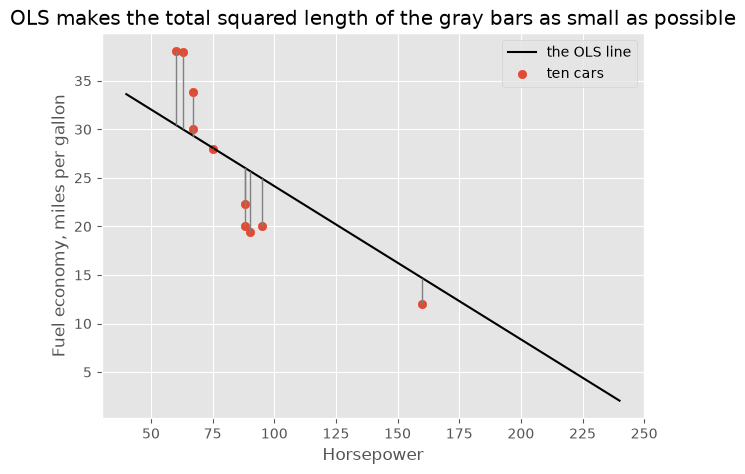

In [7]:
sample = cars.sample(10, random_state=0)
results = smf.ols("mpg ~ horsepower", data=cars).fit()

fig, ax = plt.subplots(figsize=(7, 5))

ends = pd.DataFrame({"horsepower": [40, 240]})
ax.plot(ends["horsepower"], results.predict(ends), color="black", label="the OLS line")
ax.vlines(sample["horsepower"], results.predict(sample), sample["mpg"], color="gray", linewidth=1)
ax.scatter(sample["horsepower"], sample["mpg"], label="ten cars")

ax.set_xlabel("Horsepower")
ax.set_ylabel("Fuel economy, miles per gallon")
ax.set_title("OLS makes the total squared length of the gray bars as small as possible")
ax.legend()

plt.show()

That is the whole idea behind OLS.

### Writing the model down

`statsmodels` takes the model as a **formula string**, borrowed from the statistics language R:

In [8]:
formula = "mpg ~ horsepower"

print(formula)

mpg ~ horsepower


The tilde `~` reads as *"is explained by"*. The outcome goes on the left, the explanatory variables on the right, and **you do not write the intercept** - `statsmodels` adds it for you.

Fitting happens in two steps, and it is worth seeing them separately once.

In [9]:
model = smf.ols(formula, data=cars)

model

`smf.ols` builds the model - it knows the formula and the data and has estimated nothing. `.fit()` is what actually does the arithmetic, and it returns a different object: the **results**.

In [10]:
results = model.fit()

results

From here on we chain the two together, because there is rarely a reason to hold on to an unfitted model:

```python
results = smf.ols("mpg ~ horsepower", data=cars).fit()
```

### The summary table

We apply the `summary` method on the results to actually display the regression table:

In [11]:
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.606
Model:                            OLS   Adj. R-squared:                  0.605
Method:                 Least Squares   F-statistic:                     599.7
Date:                Tue, 03 Nov 2026   Prob (F-statistic):           7.03e-81
Time:                        12:33:03   Log-Likelihood:                -1178.7
No. Observations:                 392   AIC:                             2361.
Df Residuals:                     390   BIC:                             2369.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     39.9359      0.717     55.660      0.0

That is a lot of output, and most of it is not relevant for this course. Four things are, and they are enough to read any regression you will meet in this course:

| In the table | What it tells you |
|---|---|
| **`coef`** | the estimated effect. `horsepower` is **-0.1578**: one more unit of horsepower goes with about **0.16 fewer miles per gallon** |
| **`P>\|t\|`** | how easily a relationship this strong could have come from a table with no relationship in it at all. Small means "not easily" - conventionally below 0.05 |
| **`[0.025  0.975]`** | the range of slopes the data is consistent with. Here **-0.171 to -0.145** |
| **`R-squared`** | the share of the variation in `mpg` the model accounts for. Here **0.606**, so horsepower alone explains about **61%** of why some cars use more fuel than others |

Everything else - `F-statistic`, `AIC`, `BIC`, `Omnibus`, `Durbin-Watson`, `Jarque-Bera`, `Skew`, `Kurtosis`, `Cond. No.` - is the subject of a statistics course. 

> ⚠️ **Warning:** Check `No. Observations` every single time. It says **392**, which is what we intended. Had we not dropped the missing rows ourselves, it would still say 392 but we would not have known why.

The one sentence this model supports: *among these 392 cars, a car with 10 more horsepower gets about 1.6 fewer miles to the gallon, and engine power alone accounts for about 61% of the differences between them.* Note what it does **not** say: that adding horsepower to a car *causes* its fuel economy to fall. This is simply a prediction exercise, not a claim of causality.

## What is inside a fitted model

`.summary()` is for reading. When you want to *use* a number, you take it off the results object directly.

The regression coefficients are stored in an attribute called `params`:

In [12]:
print(type(results.params))
print()
print(results.params)

<class 'pandas.Series'>

Intercept     39.935861
horsepower    -0.157845
dtype: float64


Notice that this returns a **Series**, indexed by the name of each term in the formula. Which means everything you know about a Series applies: `.loc`, arithmetic, `.round()`, and selection by label.

In [13]:
slope = results.params["horsepower"]

print(f"each extra horsepower costs {-slope:.3f} miles per gallon")
print(f"an extra 50 horsepower costs {-slope * 50:.1f} miles per gallon")

each extra horsepower costs 0.158 miles per gallon
an extra 50 horsepower costs 7.9 miles per gallon


The others follow the same pattern. `bse` is the standard error of each coefficient, `pvalues` the p-value, `tvalues` the t-statistic, and `conf_int()` - a method, not an attribute - returns the confidence interval as a **DataFrame** with a low and a high column.

In [14]:
print("standard errors:")
print(results.bse.round(4))
print()
print("p-values:")
print(results.pvalues)
print()
print("95% confidence interval:")
print(results.conf_int().round(3))

standard errors:
Intercept     0.7175
horsepower    0.0064
dtype: float64

p-values:
Intercept     1.220362e-187
horsepower     7.031989e-81
dtype: float64

95% confidence interval:
                 0       1
Intercept   38.525  41.347
horsepower  -0.171  -0.145


And the two summary numbers, which are plain floats rather than Series:

In [15]:
print("R-squared:      ", round(results.rsquared, 4))
print("adjusted R-sq.: ", round(results.rsquared_adj, 4))
print("observations:   ", int(results.nobs))

R-squared:       0.6059
adjusted R-sq.:  0.6049
observations:    392


### Building your own results table

Because those are all Series indexed the same way, a tidy table of the whole model is one `pd.DataFrame` call:

In [16]:
summary_table = pd.DataFrame({
    "coefficient": results.params,
    "std_error": results.bse,
    "p_value": results.pvalues,
    "ci_low": results.conf_int()[0],
    "ci_high": results.conf_int()[1],
}).round(4)

summary_table

,coefficient,std_error,p_value,ci_low,ci_high
Intercept,39.9359,0.7175,0.0,38.5252,41.3465
horsepower,-0.1578,0.0064,0.0,-0.1705,-0.1452


That is now an ordinary DataFrame. You can sort it, filter it, write it to Excel, or put it in a report - none of which you can do with the printed summary.

> 💡 **Tip:** `results.summary2().tables[1]` gives you almost the same thing in one line. Building it yourself is worth doing once, because it makes clear that the summary is a *display* of numbers that were already there.

<div class="alert alert-info" style="background-color:#d9edf7; border-left:6px solid #31708f; border-radius:4px; padding:12px 16px; color:#31708f;">

<h3 style="margin-top:0; color:#31708f;">Your turn</h3>

<p>Fit a model and report it in a sentence. In a single cell, load the data with the line below, fit <code>mpg ~ weight</code>, and print three things: the slope, its 95% confidence interval, and the adjusted R-squared - each labeled, and rounded to something a human would read.</p>

<pre style="background-color:#ffffff; color:#31708f; padding:8px 10px; border-radius:3px;"><code>cars = load_cars()</code></pre>

<p>Then write, in a comment, the one sentence the model supports.</p>

</div>

In [39]:
cars = load_cars()
model = smf.ols(formula="mpg ~ weight", data = cars)

result = model.fit()

print("95% confidence interval: [", result.conf_int().loc["weight", 0].round(3), ",", result.conf_int().loc["weight", 1].round(3),"]")
print("Slope:", round(result.params["weight"], 4))
print("Adj. R-squared:", result.rsquared_adj.round(3))

95% confidence interval: [ -0.008 , -0.007 ]
Slope: -0.0076
Adj. R-squared: 0.692


## The line, and what it misses

A fitted model can tell you what it *thinks* `mpg` should be for any car you describe to it. That is `predict`, and it takes a DataFrame with the columns the formula mentions.

This section draws three figures:

- **the fitted line** over the scatter - what the model says
- **observed against fitted** - which cars it is wrong about, in miles per gallon
- **residuals against fitted** - whether the shape of the model is right

The first only works with one explanatory variable: with two or more there is no single line to draw. The other two work for any model, however many variables it has, which is why they are the two worth learning.

As in every section from here on, we start from fresh data and refit the model we need:

In [40]:
cars = load_cars()
results = smf.ols("mpg ~ horsepower", data=cars).fit()

### Drawing the fitted line

We can apply the `predict` method on the results to calculate the *predicted* miles per gallon for the *observed* horsepower for each car in the data. This is known as **in-sample** prediction and it returns a numpy array of the predicted values.

In [41]:
results.predict()[:10]

array([19.41604569, 13.89148002, 16.25915102, 16.25915102, 17.83759835,
        8.68260382,  5.21001968,  5.99924335,  4.42079602,  9.94536168])

But we can also use the model to predict on a new set of values. This is known as **out-of-sample** prediction - the model has never seen a car with exactly 50.9 horsepower and does not need to have. Feed it a description, get back an answer.

`np.linspace(start, stop, n)` makes `n` evenly spaced numbers from `start` to `stop` - here, 100 horsepower values running across the range of the data.

In [42]:
grid = pd.DataFrame({
    "horsepower": np.linspace(cars["horsepower"].min(), cars["horsepower"].max(), 100)
})

grid["predicted"] = results.predict(grid)

grid.head().round(2)

,horsepower,predicted
0,46.00,32.68
1,47.86,32.38
2,49.72,32.09
3,51.58,31.79
4,53.43,31.50


We can now use the out-of-sample predictions to visualize the estimated regression line:

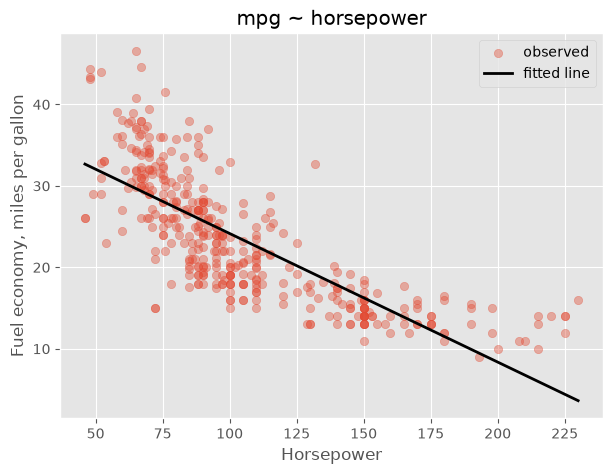

In [43]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(cars["horsepower"], cars["mpg"], alpha=0.4, label="observed")

ax.plot(grid["horsepower"], grid["predicted"], color="black", linewidth=2, label="fitted line")

ax.set_xlabel("Horsepower")
ax.set_ylabel("Fuel economy, miles per gallon")
ax.set_title("mpg ~ horsepower")
ax.legend()

plt.show()

### What the line got wrong

For the cars that *are* in the data, the model's prediction has a name and so does the miss:

- **`fittedvalues`** - what the model predicted for each row it was fitted on
- **`resid`** - the residual, `observed - predicted`, one per row

Both come back as Series aligned to the original index, so they drop straight into the table.

In [44]:
cars["fitted"] = results.fittedvalues
cars["residual"] = results.resid

cars[["name", "horsepower", "mpg", "fitted", "residual"]].head().round(2)

,name,horsepower,mpg,fitted,residual
0,chevrolet chevelle malibu,130.0,18.0,19.42,-1.42
1,buick skylark 320,165.0,15.0,13.89,1.11
2,plymouth satellite,150.0,18.0,16.26,1.74
3,amc rebel sst,150.0,16.0,16.26,-0.26
4,ford torino,140.0,17.0,17.84,-0.84


To find the cars the model is most wrong about, `.abs()` turns every residual into its size - a miss is a miss in either direction - and `.nlargest(4)` keeps the four largest. Their index labels then pick the rows out of `cars`.

In [45]:
print("mean residual:", round(cars["residual"].mean(), 10))
print()
print("the four cars the model is most wrong about:")

biggest_misses = cars["residual"].abs().nlargest(4).index
cars.loc[biggest_misses, ["name", "horsepower", "mpg", "fitted", "residual"]].round(1)

mean residual: -0.0

the four cars the model is most wrong about:


,name,horsepower,mpg,fitted,residual
322,mazda glc,65.0,46.6,29.7,16.9
329,honda civic 1500 gl,67.0,44.6,29.4,15.2
333,datsun 280-zx,132.0,32.7,19.1,13.6
154,mercury monarch,72.0,15.0,28.6,-13.6


The mean residual is zero, and always will be - OLS guarantees it, so it tells you nothing.

The individual ones do. The **Mazda GLC** has 65 horsepower and does **46.6** miles per gallon; the model predicted **29.7** and was wrong by nearly **17 mpg**. A line drawn through everything is going to be badly wrong about the cars that are unusual, and the residuals are where you find out which those are.

### Where it is wrong, in miles per gallon

Plot **observed against fitted**, and draw the line where the two would be equal: a car the model got exactly right sits on it.

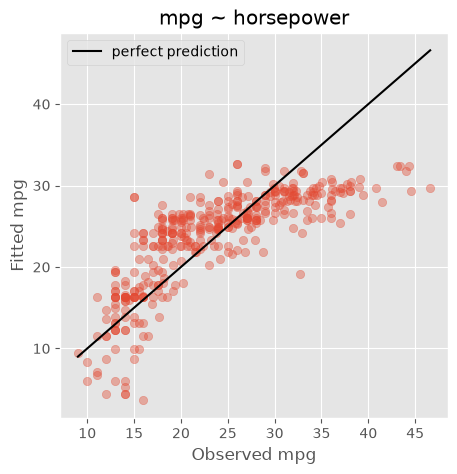

In [46]:
limits = [cars["mpg"].min(), cars["mpg"].max()]

fig, ax = plt.subplots(figsize=(5, 5))

ax.scatter(cars["mpg"], cars["fitted"], alpha=0.4)
ax.plot(limits, limits, color="black", label="perfect prediction")

ax.set_xlabel("Observed mpg")
ax.set_ylabel("Fitted mpg")
ax.set_title("mpg ~ horsepower")
ax.legend()

plt.show()

In [47]:
efficient = cars[cars["mpg"] > 35]
print(len(efficient), "cars do better than 35 mpg, and the model under-predicts",
      (efficient["residual"] > 0).sum(), "of them")

33 cars do better than 35 mpg, and the model under-predicts 33 of them


**Below the line the model under-predicts; above it, it over-predicts.** The cloud starts scattered around the line and then falls away from it entirely: every one of the 33 cars that beats 35 miles per gallon is under-predicted, some of them by more than ten.

So the model is not uniformly a bit wrong. It is close to right for ordinary cars and badly wrong about the efficient ones, and that is a different problem from noise.

### The residual plot

Plot the residuals against the fitted values. If the model is capturing the shape of the data, this should look like a shapeless cloud around zero, with no pattern left in it.

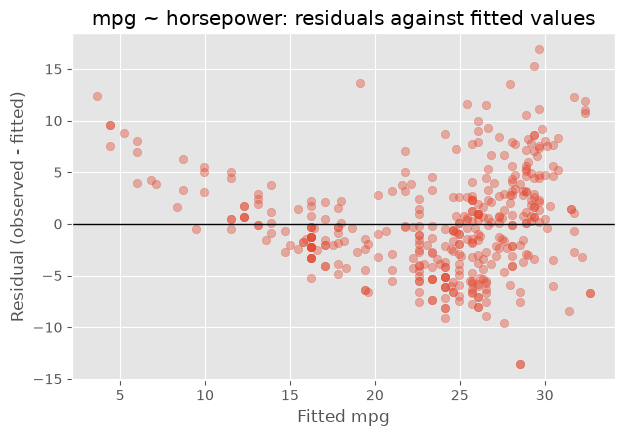

In [48]:
fig, ax = plt.subplots(figsize=(7, 4.5))

ax.scatter(cars["fitted"], cars["residual"], alpha=0.4)
ax.axhline(0, color="black", linewidth=1)

ax.set_xlabel("Fitted mpg")
ax.set_ylabel("Residual (observed - fitted)")
ax.set_title("mpg ~ horsepower: residuals against fitted values")

plt.show()

It does not look like a shapeless cloud. It curves: the residuals are **positive at both ends and negative in the middle**. 

Averaging them in bands makes it unambiguous - `pd.cut` chops a numeric column into equal-width intervals and hands back a column of interval labels, which is exactly the kind of thing `groupby` wants.

In [49]:
bands = pd.cut(cars["fitted"], 6)

cars.groupby(bands)["residual"].agg(["mean", "size"]).round(2)

,mean,size
fitted,,
"(3.603, 8.472]",6.97,11
"(8.472, 13.313]",2.15,21
"(13.313, 18.153]",-1.25,55
"(18.153, 22.994]",-1.54,48
"(22.994, 27.834]",-1.59,154
"(27.834, 32.675]",2.58,103


**+6.97, +2.15, -1.25, -1.54, -1.59, +2.58.** The model systematically under-predicts the most efficient cars and the least efficient ones, and over-predicts everything in the middle. That is not noise; that is a straight line being asked to describe something nonlinear.

> ⚠️ **Warning:** An R² of 0.61 sounds respectable, and this model is wrong in a completely predictable way. **R² does not tell you whether the shape is right.** The residual plot does, it costs three lines, and it is the single most useful diagnostic in this notebook.

<div class="alert alert-info" style="background-color:#d9edf7; border-left:6px solid #31708f; border-radius:4px; padding:12px 16px; color:#31708f;">

<h3 style="margin-top:0; color:#31708f;">Your turn</h3>

<p>Check the shape of a model. In a single cell, load the data with the line below, fit <code>mpg ~ weight</code>, and draw its residuals against its fitted values, with a horizontal line at zero, axis labels and a title.</p>

<pre style="background-color:#ffffff; color:#31708f; padding:8px 10px; border-radius:3px;"><code>cars = load_cars()</code></pre>

<p>Then say in a comment whether there is a pattern left in the residuals.</p>

</div>

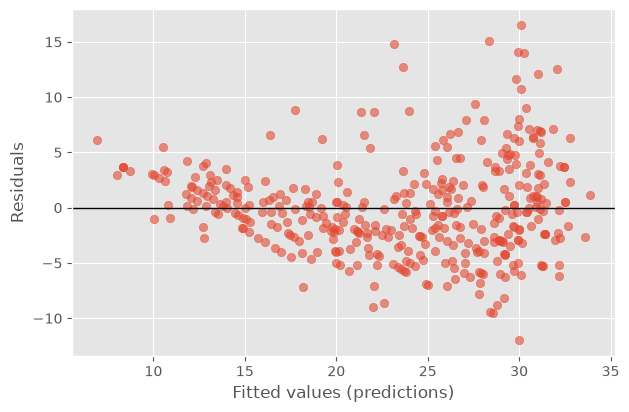

In [57]:
cars = load_cars()
model = smf.ols(formula="mpg ~ weight", data=cars)

# fit model
results = model.fit()

# draw residuals
fig, ax = plt.subplots(figsize=(7,4.5))

ax.scatter(results.fittedvalues, results.resid, alpha=0.6) # (x,y) = x and y axis
ax.axhline(0, color="black", lw=1)
ax.set_ylabel("Residuals")
ax.set_xlabel("Fitted values (predictions)")
plt.show()

seems to be a pattern in the residuals (not a shapeless cloud)

## More than one explanatory variable

Fuel economy does not depend only on engine power. Add a second variable to the right-hand side of the formula with a `+`.

`simple` is the same model we have been calling `results`; the new name only tells it apart from the second one.

In [58]:
cars = load_cars()

simple = smf.ols("mpg ~ horsepower", data=cars).fit()
multiple = smf.ols("mpg ~ horsepower + weight", data=cars).fit()

print(multiple.summary())

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.706
Model:                            OLS   Adj. R-squared:                  0.705
Method:                 Least Squares   F-statistic:                     467.9
Date:                Tue, 03 Nov 2026   Prob (F-statistic):          3.06e-104
Time:                        13:31:07   Log-Likelihood:                -1121.0
No. Observations:                 392   AIC:                             2248.
Df Residuals:                     389   BIC:                             2260.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     45.6402      0.793     57.540      0.0

Read the `weight` coefficient the way you read any of them, with the units attached: **-0.0058 miles per gallon per pound**, which is easier to think about multiplied up - about **0.58 mpg per extra 100 pounds**.

Now look at what happened to `horsepower`.

In [59]:
print("horsepower alone        :", round(simple.params["horsepower"], 4))
print("horsepower beside weight:", round(multiple.params["horsepower"], 4))
print()
print("correlation, horsepower and weight:", round(cars["horsepower"].corr(cars["weight"]), 3))

horsepower alone        : -0.1578
horsepower beside weight: -0.0473

correlation, horsepower and weight: 0.865


**The coefficient falls by two thirds**, from -0.158 to -0.047, and the reason is the third number, the same `.corr()` we computed before fitting the first line: horsepower and weight have a correlation of **0.865**. Powerful engines go in heavy cars.

So in the simple model, `horsepower` was not measuring horsepower. It was measuring horsepower *and the weight that comes with it*, because there was nothing else in the model to take the credit. Adding `weight` splits the effect between them, and the honest reading of the multiple regression is **"comparing two cars of the same weight, the one with 10 more horsepower gets about 0.5 mpg less"**.

### R², and why there are two of them

In [60]:
print("R-squared           :", round(simple.rsquared, 4), "->", round(multiple.rsquared, 4))
print("adjusted R-squared  :", round(simple.rsquared_adj, 4), "->", round(multiple.rsquared_adj, 4))

R-squared           : 0.6059 -> 0.7064
adjusted R-squared  : 0.6049 -> 0.7049


`R-squared` can only ever go **up** when you add a variable. Even a column of random numbers will improve the fit a little, because with one more knob to turn the model can bend a little closer to the data it was fitted on.

`Adj. R-squared` subtracts a penalty for the number of variables, which is why it is the one to quote when you are comparing models of different sizes.

> ⚠️ **Warning:** That penalty is mild. Adjusted R² discourages complexity; it does not detect nonsense. **Neither number can tell you whether a variable belongs in your model.** That is a judgment about the subject, and it is yours to make.

<div class="alert alert-info" style="background-color:#d9edf7; border-left:6px solid #31708f; border-radius:4px; padding:12px 16px; color:#31708f;">

<h3 style="margin-top:0; color:#31708f;">Your turn</h3>

<p>Watch a coefficient move. In a single cell, load the data with the line below and fit two models: <code>mpg ~ horsepower + weight</code> and then the same model with <code>model_year</code> added. Print the <code>horsepower</code> coefficient and its p-value from each, and the adjusted R-squared of each.</p>

<pre style="background-color:#ffffff; color:#31708f; padding:8px 10px; border-radius:3px;"><code>cars = load_cars()</code></pre>

<p>Then say in a comment what happened to horsepower, and why that is not a reason to leave <code>model_year</code> out.</p>

</div>

In [78]:
cars = load_cars()

formulas = {
    "Model 1": "mpg ~ horsepower + weight",
    "Model 2": "mpg ~ horsepower + weight + model_year",
}

for name, formula in formulas.items():
    results = smf.ols(formula=formula, data=cars).fit()

    coef = results.params["horsepower"]
    p_value = results.pvalues["horsepower"]
    r2_adj = results.rsquared_adj

    print(name)
    print(f"  Coefficient (horsepower): {coef:.4f}")
    print(f"  P-value:                  {p_value:.4f}")
    print(f"  Adjusted R-squared:       {r2_adj:.4f}")
    print()


Model 1
  Coefficient (horsepower): -0.0473
  P-value:                  0.0000
  Adjusted R-squared:       0.7049

Model 2
  Coefficient (horsepower): -0.0050
  P-value:                  0.5966
  Adjusted R-squared:       0.8068



As we can see, the coefficient is no longer significant. In model 1 it was -0.0473 and significant. In model 2 it is -0,005 and non-significant.

## Curves: polynomials and logs

The residual plot told us the straight line is the wrong shape. This section changes the shape in two ways, both of which are still *linear regression* - the model has to be linear in its **coefficients**, not in its variables:

- a **polynomial** adds a squared term, so the line can bend
- a **log** changes the scale a variable is measured on, and with it what the coefficient means

### A polynomial

Add the square of the explanatory variable. In a formula, anything wrapped in `I()` is computed first and then treated as a variable of its own, so `I(horsepower**2)` is "horsepower, squared".

In [79]:
cars = load_cars()

simple = smf.ols("mpg ~ horsepower", data=cars).fit()
poly = smf.ols("mpg ~ horsepower + I(horsepower**2)", data=cars).fit()

poly.params.round(5)

Intercept             56.90010
horsepower            -0.46619
I(horsepower ** 2)     0.00123
dtype: float64

Let us add both regression lines (from the simple and the polynomial model) to the scatter plot:

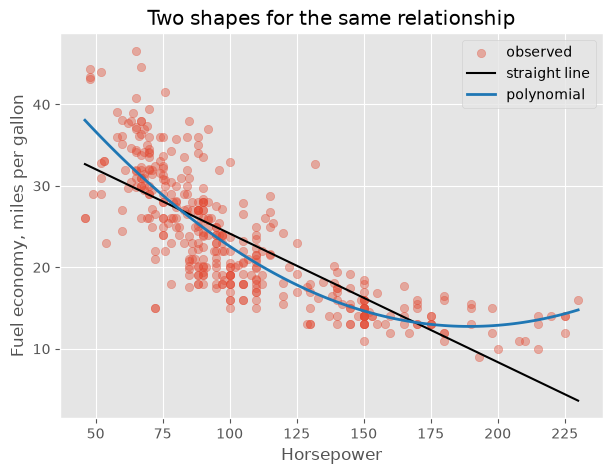

In [80]:
grid = pd.DataFrame({
    "horsepower": np.linspace(cars["horsepower"].min(), cars["horsepower"].max(), 100)
})

fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(cars["horsepower"], cars["mpg"], alpha=0.4, label="observed")
ax.plot(grid["horsepower"], simple.predict(grid), color="black", label="straight line")
ax.plot(grid["horsepower"], poly.predict(grid), color="tab:blue", linewidth=2, label="polynomial")

ax.set_xlabel("Horsepower")
ax.set_ylabel("Fuel economy, miles per gallon")
ax.set_title("Two shapes for the same relationship")
ax.legend()

plt.show()

The curve follows the cloud much better. The residual plot from earlier, drawn again for the polynomial, says the same:

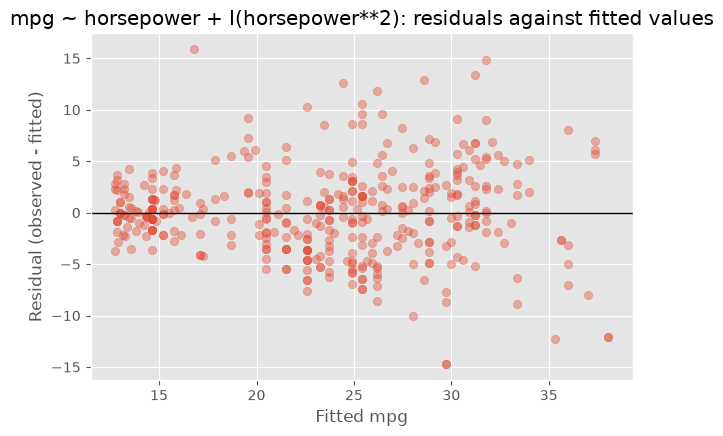

In [81]:
fig, ax = plt.subplots(figsize=(7, 4.5))

ax.scatter(poly.fittedvalues, poly.resid, alpha=0.4)
ax.axhline(0, color="black", linewidth=1)

ax.set_xlabel("Fitted mpg")
ax.set_ylabel("Residual (observed - fitted)")
ax.set_title("mpg ~ horsepower + I(horsepower**2): residuals against fitted values")

plt.show()

The U is gone: the residuals now sit around zero across most of the range, and R² rises from **0.606** to **0.688**. A residual plot with no pattern left in it does not prove that the model is right - but it no longer has a complaint about the *shape*.

> ⚠️ **Warning:** A fitted model describes the range it was fitted on. The most powerful car in the data has 230 horsepower. Ask either model about a 400-horsepower car and it answers anyway: the straight line predicts **-23 mpg**, and the polynomial - a parabola has to turn somewhere - predicts **+67 mpg**. Both are nonsense, in opposite directions, and both look like ordinary numbers. A model cannot refuse to extrapolate, so check the range of your explanatory variables before you predict anything.

### A log

A log is the other way to change the shape. You met it as an axis scale when we plotted emissions against GDP: GDP runs from a few hundred dollars to over a hundred thousand, and only a log axis spread the countries out. In a regression the log changes the *model*, not just the picture.

`np.log()` works directly inside a formula string. Put it on **both** sides and the coefficient becomes an **elasticity**: the percentage change in the outcome that goes with a one-percent change in the explanatory variable.

In [82]:
log_log = smf.ols("np.log(mpg) ~ np.log(horsepower)", data=cars).fit()

elasticity = log_log.params["np.log(horsepower)"]

print("elasticity:", round(elasticity, 3))
print(f"1% more horsepower goes with about {-elasticity:.2f}% worse fuel economy")
print()
print("R-squared:", round(log_log.rsquared, 3))

elasticity: -0.842
1% more horsepower goes with about 0.84% worse fuel economy

R-squared: 0.723


That is a genuinely useful sentence, and it needs no units - which is why economists reach for logs so often.

> 💡 **Tip:** A log on the right-hand side only, `mpg ~ np.log(horsepower)`, is allowed too. It bends the line in a way that keeps falling but never turns back, but its coefficient is harder to put into words, which is why the log on both sides is the one people quote. And if you prefer, create the column first - `cars["log_hp"] = np.log(cars["horsepower"])` - and use `log_hp` in the formula. The fit is identical.

> ⚠️ **Warning:** That R² of **0.723** is **not** comparable to the 0.688 above it. R² is the share of the variation *in the dependent variable* that the model explains - and the dependent variable here is `log(mpg)`, a different quantity. **You may only compare R² across models that explain the same thing on the same rows.**

<div class="alert alert-info" style="background-color:#d9edf7; border-left:6px solid #31708f; border-radius:4px; padding:12px 16px; color:#31708f;">

<h3 style="margin-top:0; color:#31708f;">Your turn</h3>

<p>Bend a line. In a single cell, load the data with the line below and fit two models of <code>mpg</code> on <code>weight</code>: a straight line and a second-order polynomial. Draw both fitted curves over the scatter on one set of axes - predicting on a grid of 100 weights from <code>np.linspace</code> - with axis labels and a legend.</p>

<pre style="background-color:#ffffff; color:#31708f; padding:8px 10px; border-radius:3px;"><code>cars = load_cars()</code></pre>

</div>

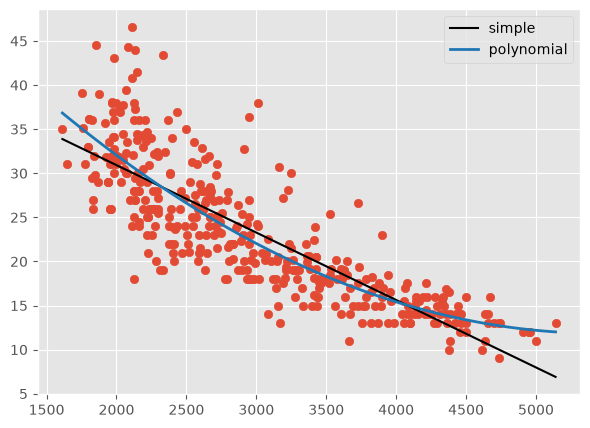

In [95]:
cars = load_cars()

simple = smf.ols(formula="mpg ~ weight", data=cars).fit()
poly = smf.ols(formula="mpg ~ weight + I(weight**2)", data=cars).fit()

# plot regression lines
grid = pd.DataFrame({"weight":np.linspace(cars["weight"].min(), cars["weight"].max(), 100)})

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(cars["weight"], cars["mpg"])
ax.plot(grid["weight"], simple.predict(grid), color="black", label="simple")
ax.plot(grid["weight"], poly.predict(grid), color="tab:blue", linewidth=2, label="polynomial")

ax.legend()
plt.show()

## Variables that are not numbers

`origin` says where a car was built. It is text, it has three values, and there is no sense in which `japan` is larger than `europe` - so it cannot go into a formula as it stands.

In [96]:
cars["origin"].value_counts()

origin
usa       245
japan      79
europe     68
Name: count, dtype: int64

Wrapping it in `C()` tells `statsmodels` to treat it as a **category**: instead of one slope, it fits a separate **intercept** for each group.

In [97]:
cars = load_cars()

by_origin = smf.ols("mpg ~ horsepower + C(origin)", data=cars).fit()

by_origin.params.round(4)

Intercept             38.3695
C(origin)[T.japan]     2.7510
C(origin)[T.usa]      -2.4253
horsepower            -0.1336
dtype: float64

Three coefficients where you might have expected four, and the missing one is the point.

**One category is left out and becomes the baseline** - here `europe`, because `C()` takes them in alphabetical order and drops the first. The `Intercept` of **38.37** *is* Europe, and the other two are measured **against** it:

| | Reading |
|---|---|
| `Intercept` = 38.37 | a European car with zero horsepower (a fiction, but the anchor for the line) |
| `C(origin)[T.japan]` = **+2.75** | at the same horsepower, a Japanese car does 2.75 mpg **more** than a European one |
| `C(origin)[T.usa]` = **-2.43** | at the same horsepower, an American car does 2.43 mpg **less** |
| `horsepower` = -0.134 | the slope, and it is **the same for all three groups** |

That last line is what the model assumes, and it is easiest to see drawn.

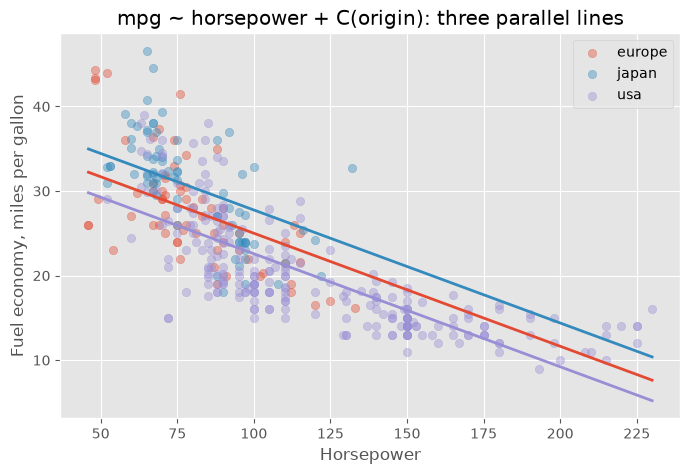

In [98]:
grid = pd.DataFrame({
    "horsepower": np.linspace(cars["horsepower"].min(), cars["horsepower"].max(), 100)
})

fig, ax = plt.subplots(figsize=(8, 5))

# Scatter plot by origin
for origin, group in cars.groupby("origin"):
    ax.scatter(group["horsepower"], group["mpg"], alpha=0.4, label=origin)

# Regression line by origin
for origin in sorted(cars["origin"].unique()):
    line_grid = grid.copy()
    line_grid["origin"] = origin
    ax.plot(line_grid["horsepower"], by_origin.predict(line_grid), linewidth=2)

ax.set_xlabel("Horsepower")
ax.set_ylabel("Fuel economy, miles per gallon")
ax.set_title("mpg ~ horsepower + C(origin): three parallel lines")
ax.legend()

plt.show()

**Three lines, and they are parallel by construction.** `C(origin)` moves a line up and down; it cannot tilt it.

### Interactions: letting the slope change too

If you think the *relationship* differs between groups - not just the level - you need an interaction.

Written with `*` instead of `+`, which adds the variables **and** their product.

In [99]:
interacted = smf.ols("mpg ~ horsepower * C(origin)", data=cars).fit()

interacted.params.round(4)

Intercept                        45.4737
C(origin)[T.japan]                3.3425
C(origin)[T.usa]                -10.9972
horsepower                       -0.2218
horsepower:C(origin)[T.japan]    -0.0082
horsepower:C(origin)[T.usa]       0.1005
dtype: float64

Now there are two extra terms, `horsepower:C(origin)[T.japan]` and `horsepower:C(origin)[T.usa]`, and they are **adjustments to the slope**. The baseline slope of -0.2218 belongs to Europe; each group's own slope is that plus its adjustment.

In [100]:
baseline = interacted.params["horsepower"]

print("europe:", round(baseline, 4))
print("japan :", round(baseline + interacted.params["horsepower:C(origin)[T.japan]"], 4))
print("usa   :", round(baseline + interacted.params["horsepower:C(origin)[T.usa]"], 4))

europe: -0.2218
japan : -0.23
usa   : -0.1213


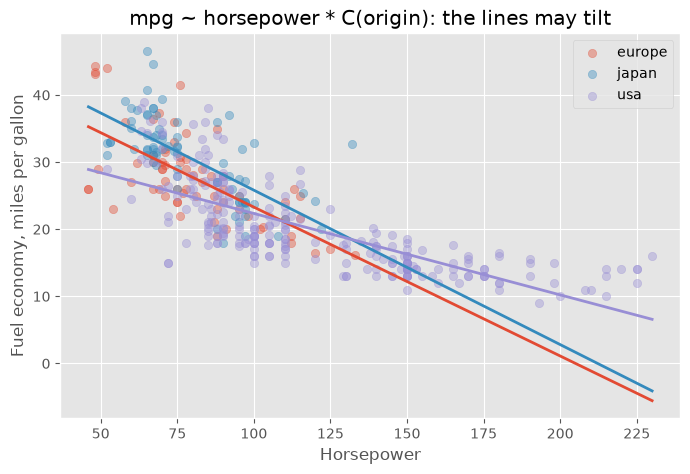

In [101]:
fig, ax = plt.subplots(figsize=(8, 5))

# Scatter plot by origin
for origin, group in cars.groupby("origin"):
    ax.scatter(group["horsepower"], group["mpg"], alpha=0.4, label=origin)

# Regression line by origin
for origin in sorted(cars["origin"].unique()):
    line_grid = grid.copy()
    line_grid["origin"] = origin
    ax.plot(line_grid["horsepower"], interacted.predict(line_grid), linewidth=2)

ax.set_xlabel("Horsepower")
ax.set_ylabel("Fuel economy, miles per gallon")
ax.set_title("mpg ~ horsepower * C(origin): the lines may tilt")
ax.legend()

plt.show()

The American line is now visibly flatter: **-0.121** against **-0.222** for Europe and **-0.230** for Japan. An extra 50 horsepower costs a European car about 11 mpg and an American car about 6.

Whether that is a fact about engineering or about which cars ended up in this sample, the model cannot say. What it can say is that assuming one slope for all three - which is what the parallel-lines model above does - is assuming something the data disagrees with.

### Do the slopes really differ?

The model can answer that itself. Each interaction term measures how far one group's slope is from the baseline's, so its p-value answers *"is this group's slope different from Europe's?"*

In [102]:
interacted.pvalues.round(4)

Intercept                        0.0000
C(origin)[T.japan]               0.2966
C(origin)[T.usa]                 0.0000
horsepower                       0.0000
horsepower:C(origin)[T.japan]    0.8327
horsepower:C(origin)[T.usa]      0.0003
dtype: float64

The American adjustment has a p-value of **0.0003**, and the Japanese one **0.83**. So the data give good reason to think American cars have a different slope from European ones, and no reason to think Japanese cars do.

That is what an interaction is for: a question about whether groups behave differently becomes a coefficient in the table, and the table tests it for you.

<div class="alert alert-info" style="background-color:#d9edf7; border-left:6px solid #31708f; border-radius:4px; padding:12px 16px; color:#31708f;">

<h3 style="margin-top:0; color:#31708f;">Your turn</h3>

<p>Read a category. In a single cell, load the data with the line below, fit <code>mpg ~ weight + C(origin)</code>, and print its coefficients.</p>

<pre style="background-color:#ffffff; color:#31708f; padding:8px 10px; border-radius:3px;"><code>cars = load_cars()</code></pre>

<p>Then say in a comment what the <code>C(origin)[T.usa]</code> coefficient means - in miles per gallon, and compared with which cars.</p>

</div>

In [105]:
cars = load_cars()

by_origin = smf.ols(formula="mpg ~ weight + C(origin)", data=cars).fit()

print(by_origin.params.round(4))

Intercept             44.7031
C(origin)[T.japan]     1.3562
C(origin)[T.usa]      -0.9709
weight                -0.0070
dtype: float64


## Fitting many models at once

Every model so far has been one formula, typed by hand, in its own cell. That is fine for three models and unmanageable for thirty - and thirty is normal, because deciding what belongs in a model means fitting a lot of models that do not.

A formula is a **string**. Strings can be built, and anything that can be built can be built in a loop. Two loops are worth knowing:

- **Varying the specification** - the same outcome, with explanatory variables added one at a time or swapped for one another. This is how you see what each variable does to the others.
- **Varying the rows** - the same model, refitted with some observations left out each time, to see how much the answer depends on them.

### One variable at a time

Recall that `.join()` glues a list of strings together with the string you call it on in between. So `" + ".join(names)` turns a list of column names into the right-hand side of a formula. Add one name at a time and you get a sequence of nested models, each containing the last.

In [106]:
cars = load_cars()

predictors = ["horsepower", "weight", "C(origin)", "model_year"]

specifications = []

for i in range(1, len(predictors) + 1):
    right_hand_side = " + ".join(predictors[:i])
    specifications.append(f"mpg ~ {right_hand_side}")

for spec in specifications:
    print(spec)

mpg ~ horsepower
mpg ~ horsepower + weight
mpg ~ horsepower + weight + C(origin)
mpg ~ horsepower + weight + C(origin) + model_year


In [107]:
fitted_models = [smf.ols(spec, data=cars).fit() for spec in specifications]

comparison = pd.DataFrame({
    "specification": specifications,
    "adj_r_squared": [m.rsquared_adj for m in fitted_models],
    "horsepower": [m.params["horsepower"] for m in fitted_models],
    "hp_p_value": [m.pvalues["horsepower"] for m in fitted_models],
}).round(4)

comparison

,specification,adj_r_squared,horsepower,hp_p_value
0,mpg ~ horsepower,0.6049,-0.1578,0.0000
1,mpg ~ horsepower + weight,0.7049,-0.0473,0.0000
2,mpg ~ horsepower + weight + C(origin),0.7164,-0.0535,0.0000
3,mpg ~ horsepower + weight + C(origin) + model_...,0.8171,-0.0085,0.3646


Four models built by a loop, and the table says something none of the four summaries says on its own:

**`horsepower` starts at -0.158 with a p-value of zero and ends at -0.009 with a p-value of 0.36.**

Once weight, origin and model year are in the room, engine power has nothing left to explain - and the adjusted R² has climbed from 0.605 to 0.817 anyway. Whether that means horsepower does not matter, or that it only ever mattered through the weight and the era it came with, is not a question the arithmetic answers - but you would never have seen it by reading one summary at a time.

<div class="alert alert-info" style="background-color:#d9edf7; border-left:6px solid #31708f; border-radius:4px; padding:12px 16px; color:#31708f;">

<h3 style="margin-top:0; color:#31708f;">Your turn</h3>

<p>Grow a model in a loop. In a single cell, load the data with the line below. Starting from <code>mpg ~ weight</code>, add <code>horsepower</code>, then <code>acceleration</code>, then <code>C(origin)</code>, one at a time - building each formula in a loop rather than typing it out. Collect each specification, its adjusted R-squared and its coefficient on <code>weight</code> into one DataFrame.</p>

<pre style="background-color:#ffffff; color:#31708f; padding:8px 10px; border-radius:3px;"><code>cars = load_cars()</code></pre>

</div>

In [ ]:
cars = load_cars()

predictors = ["weight", "horsepower", "acceleration", "C(origin)"]

specifications = []

# loop over model specifications
for i in range(1, len(predictors) + 1):
    right_hand_side = " + ".join(predictors[:i])
    specifications.append(f"mpg ~ {right_hand_side}")

fitted_models = [smf.ols(spec, data=cars).fit() for spec in specifications]

comparison = pd.DataFrame({
    "specification": specifications,
    "adj_r_squared": [m.rsquared_adj for m in fitted_models],
    "weight": [m.params["weight"] for m in fitted_models]
}).round(4)

comparison

mpg ~ weight
mpg ~ weight + horsepower
mpg ~ weight + horsepower + acceleration
mpg ~ weight + horsepower + acceleration + C(origin)


,specification,adj_r_squared,weight
0,mpg ~ weight,0.6918,-0.0076
1,mpg ~ weight + horsepower,0.7049,-0.0058
2,mpg ~ weight + horsepower + acceleration,0.7041,-0.0058
3,mpg ~ weight + horsepower + acceleration + C(o...,0.7157,-0.0048


## Getting the results out

A result that only exists inside a notebook cannot go in a report. Three kinds of thing need to leave, and each has its own tool.

### A table of numbers

Anything that is a DataFrame goes out with `to_excel`. For example, we can generate a table of summary statistics and store this in a spreadsheet.

In [127]:
cars = load_cars()

summary = (
    cars
    .groupby("origin")
    .agg(
        cars=("mpg", "size"),
        mean_mpg=("mpg", "mean"),
        mean_horsepower=("horsepower", "mean"),
        mean_weight=("weight", "mean"),
    )
    .round(1)
    .reset_index()
)

summary.to_excel("mpg-summary.xlsx", index=False)
print("written")
summary

written


,origin,cars,mean_mpg,mean_horsepower,mean_weight
0,europe,68,27.6,80.6,2433.5
1,japan,79,30.5,79.8,2221.2
2,usa,245,20.0,119.0,3372.5


`index=False` because the index here is just row numbers and nobody wants a column of them in a spreadsheet.

`to_csv` and `to_html` work exactly the same way if you want a plain-text or a web version instead.

Like every file this notebook writes, `mpg-summary.xlsx` is **derived**: running the notebook makes it again, so it lives next to the notebook and never in `data/`.

### A regression table

A table of *models* is a different shape: one column per specification, coefficients stacked with their standard errors underneath. Building that by hand is tedious, and `statsmodels` will do it - `summary_col` takes a list of fitted models.

Here are the four models from the specification loop, refitted so that this section does not depend on what the exercise above it left behind:

In [ ]:
# the standard way of displaying output of a regression model

from statsmodels.iolib.summary2 import summary_col

specifications = [
    "mpg ~ horsepower",
    "mpg ~ horsepower + weight",
    "mpg ~ horsepower + weight + C(origin)",
    "mpg ~ horsepower + weight + C(origin) + model_year",
]
fitted_models = [smf.ols(spec, data=cars).fit() for spec in specifications]

regression_table = summary_col(
    fitted_models,
    stars=True,
    float_format="%0.3f",
    model_names=["(1)", "(2)", "(3)", "(4)"],
    regressor_order=["horsepower", "weight", "model_year"],
)

regression_table

,(1),(2),(3),(4)
horsepower,-0.158***,-0.047***,-0.054***,-0.008
,(0.006),(0.011),(0.011),(0.009)
weight,,-0.006***,-0.005***,-0.006***
,,(0.001),(0.001),(0.000)
model_year,,,,0.754***
,,,,(0.052)
Intercept,39.936***,45.640***,43.701***,-15.266***
,(0.717),(0.793),(0.932),(4.099)
C(origin)[T.japan],,,1.781**,0.328
,,,(0.696),(0.568)


That is the standard shape of a regression table in economics: specifications across the top, variables down the side, standard errors in parentheses and stars for significance. Reading across the `horsepower` row tells the story of the specification loop in one glance.

A few arguments earn their place:
- `stars=True` adds the significance markers
- `float_format` stops it printing fifteen decimal places
- `model_names` replaces the default labels
- `regressor_order` puts the variables you care about at the top instead of leaving them alphabetical

It goes to a file in more than one format. `as_latex` writes it as LaTeX, for a document typeset in LaTeX. `as_html` writes it as an HTML table, which opens in a browser and pastes into Word with its structure intact - usually the more useful of the two. And `as_text` gives you the plain version you are looking at now.

Each of them returns one long string, and writing a string to a file takes one more construction: `open(name, "w")` opens a file for writing, `file.write()` puts the string into it, and `with` closes the file again as soon as the indented block ends.

In [ ]:
with open("regression-table.tex", "w") as file:
    file.write(regression_table.as_latex())

with open("regression-table.html", "w") as file:
    file.write(regression_table.as_html())

print("written")

> 💡 **Tip:** There is also a package called **stargazer**, a port of the R tool of the same name, which produces a slightly prettier LaTeX table. It has to be installed separately, so it is not part of this course's environment.

## Making your analysis reproducible

That is the last method of the course. The last idea is what all of it was for.

Everything in this notebook - the model, the table, the figures - is worth exactly as much as somebody else's ability to reproduce it. A result nobody can regenerate is an opinion with numbers in it. The whole point of doing analysis in code rather than in a spreadsheet is that the code *is* the record: run it again and you get the same answer, or you find out why not.

That only holds if you write it so it holds:

| For your work to be reproducible | Where it came from |
|---|---|
| **Imports at the top**, once, followed by anything that applies to the whole notebook | every notebook in this course |
| Data you load more than once is loaded by **a function**, so every load makes the same decisions | `load_panel` when we plotted, and `load_cars` here |
| Code you would otherwise copy and paste is **a function**, written once and called | functions |
| **Relative paths**, never `C:\Users\yourname\Desktop\...` | setting up conda, and every `../data/` since |
| It **runs top to bottom from a fresh kernel** - execution order is not document order | the tour of notebooks at the very start |
| The **environment is written down**, not remembered | setting up conda |
| The **raw data is only ever read** - never edited by hand, never written over by code | pandas basics |
| Every step that changes the data is **in the code**, including the ones you regret | wrangling |
| Anything the notebook makes, the notebook can make again - so it goes **next to the notebook**, never into the data | pandas basics, plotting, regression |
| The **result leaves as a file**, not a screenshot | regression |

None of those is about statistics, and none is optional. Restart your kernel and run the whole thing before you call anything finished - it is the only test that matters, and it fails more often than anybody expects.

## Additional resources

- [statsmodels: fitting models using R-style formulas](https://www.statsmodels.org/stable/example_formulas.html) - everything the formula string can express, including `:`, `*`, `I()` and `C()`
- [statsmodels: linear regression](https://www.statsmodels.org/stable/regression.html) - the full list of what a fitted results object carries
- [pandas: IO tools](https://pandas.pydata.org/docs/user_guide/io.html) - every `read_*` and `to_*` pandas has, in one table
- [SKL401](https://isabelhovdahl.github.io/skl401/) - topic 5 covers the same ground: 5.1 regression, 5.2 model objects, 5.3 running many models, including the loop over subgroups that the home exercises take up, and **5.4 exporting tables**, which demonstrates the stargazer package mentioned above

**That is the course.** You can write a program, keep it in version control, build an environment somebody else can rebuild, read a real file into a table, clean it, summarize it, join it to another one, draw it, model it, and hand the whole thing to someone who can run it. Everything after this is more of the same, with better questions.